In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
import sys
import os
sys.path.append(os.path.abspath('../'))

In [2]:
import albumentations as A
from albumentations.pytorch import ToTensorV2
import math
import numpy as np
import torch

from datasets import ReBENDataset
from utils.features import HOGLayer, HOGSaliency, NDILayer, NDISaliency
from utils.visualization import plot_images, quant_norm, generate_saliency_grid, generate_hog_image

# ------------------------------------------------
REBEN_LMDB_PATH = "/mnt/ssd/datasets/reben/BigEarthNet-S2-3%_lmdb"
REBEN_KEYS_PATH = "/mnt/ssd/datasets/reben/keys-3%.pkl"
split_file = "../datasets/splits/reben.parquet"

BANDS = ["B01", "B02", "B03", "B04", "B05", "B06",
         "B07", "B08", "B8A", "B09", "B11", "B12"]
BATCH_SIZE = 64
IMG_SIZE= 112

NORMALIZE = False # !!!!!!!!!!!!!!!!!!! crucial for NDI

COMBINATIONS = {
    "true_color": ["B04", "B03", "B02"],
    "red_edge": ["B07", "B06", "B05"],
    "vegetation": ["B08"],#, "B04", "B03"],
    "moisture_composite": ["B8A", "B11", "B12"]}
band_indices = {name: [BANDS.index(b) for b in bands] for name, bands in COMBINATIONS.items()}

ds = ReBENDataset(
    data_dir=REBEN_LMDB_PATH, keys_path= REBEN_KEYS_PATH,
    align_size=(120, 120), bands=BANDS,
    normalize=NORMALIZE, transform=A.Compose([A.CenterCrop(height=IMG_SIZE, width=IMG_SIZE), ToTensorV2()]),
    split_file=split_file, split="validation",
    return_mask=False)

imgs_batch = torch.stack([ds[i].float() for i in range(10, 10+BATCH_SIZE)])


/home/jacer/myPrograms/miniforge3/envs/rs_mae/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch.Size([12, 9, 28, 28])


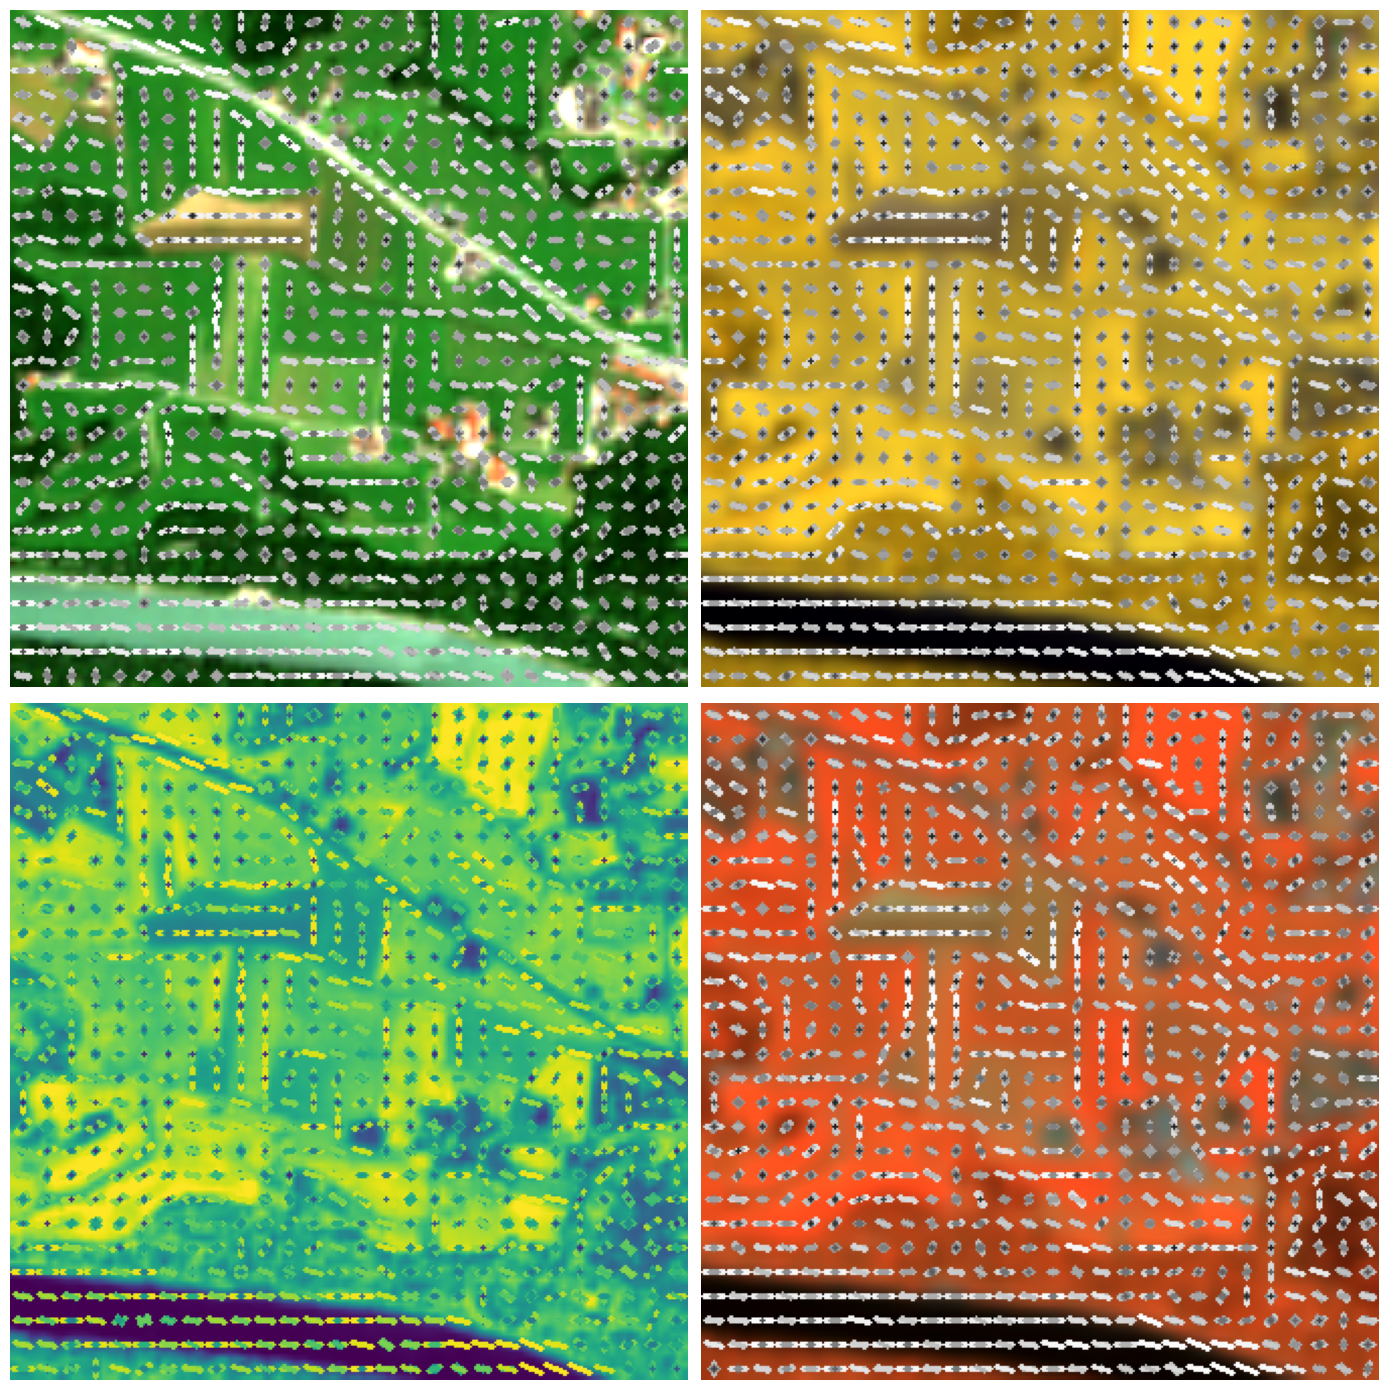

In [7]:
NBINS = 9
POOL = 4
hog_layer = HOGLayer(nbins=NBINS, pool=POOL, in_channels=len(BANDS),
                     gaussian_window=None, normalize=True)

hog_grids_batch = hog_layer(imgs_batch)


scale_factor = 3
imgs = torch.nn.functional.interpolate(imgs_batch, scale_factor=scale_factor, mode='bilinear', align_corners=False)


INDEX = 0
img = imgs[INDEX]
hog_grids = hog_grids_batch[INDEX]
print(hog_grids.shape)
hog_grid_true_color = hog_grids[band_indices['true_color'], ...]
hog_grid_red_edge = hog_grids[band_indices['red_edge'], ...]
hog_grid_vegetation = hog_grids[band_indices['vegetation'], ...]
hog_grid_moisture_composite = hog_grids[band_indices['moisture_composite'], ...]

plot_images([generate_hog_image(hog_grid_true_color, image=quant_norm(img[band_indices['true_color'], ...])),
             generate_hog_image(hog_grid_red_edge, image=quant_norm(img[band_indices['red_edge'], ...])),
             generate_hog_image(hog_grid_vegetation, image=quant_norm(img[band_indices['vegetation'], ...])),
             generate_hog_image(hog_grid_moisture_composite, image=quant_norm(img[band_indices['moisture_composite'], ...]))])#, ncols=3)

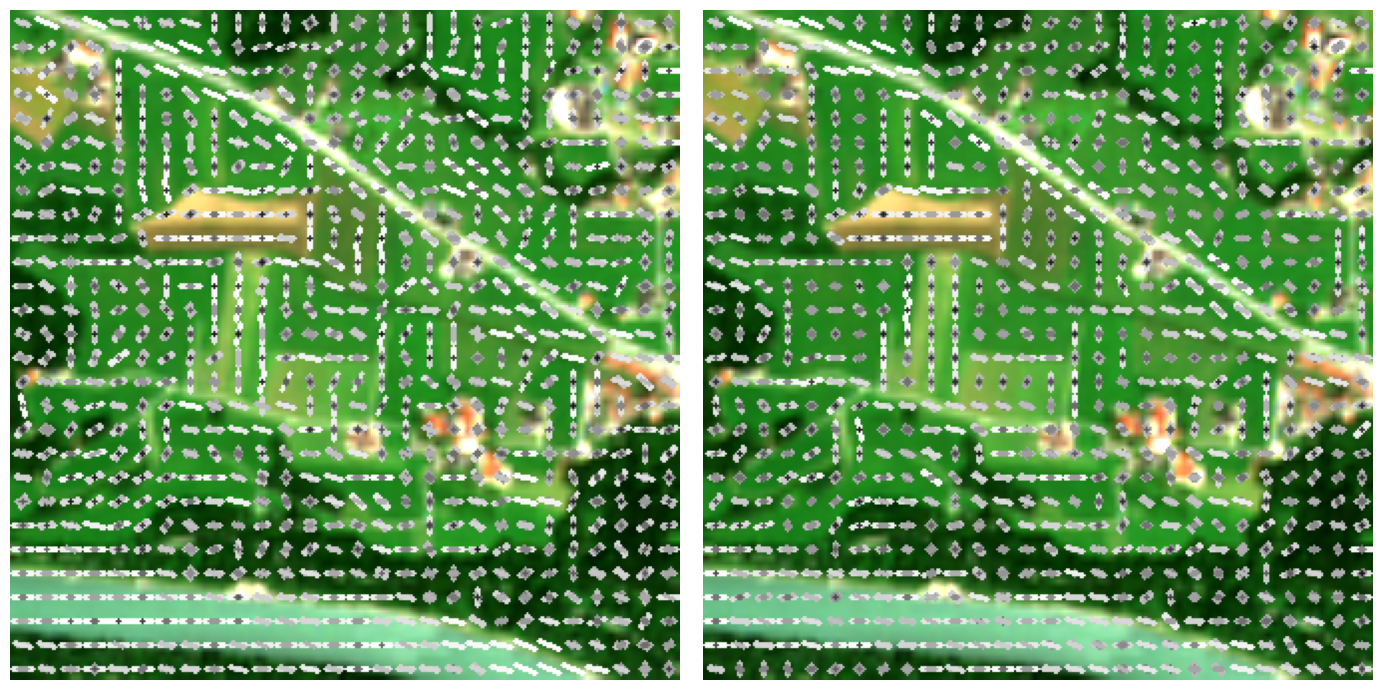

In [8]:
NBINS = 9
POOL = 4
hog_layer = HOGLayer(nbins=NBINS, pool=POOL, in_channels=len(BANDS), use_max_gradient=True,
                     gaussian_window=None, normalize=True)

hog_grids_batch = hog_layer(imgs_batch)


scale_factor = 3
imgs = torch.nn.functional.interpolate(imgs_batch, scale_factor=scale_factor, mode='bilinear', align_corners=False)


INDEX = 0
img = imgs[INDEX]
hog_grids = hog_grids_batch[INDEX]

tmp_band_indices = [0]
hog_grid_max = hog_grids[tmp_band_indices, ...]

plot_images([generate_hog_image(hog_grid_max, image=quant_norm(img[band_indices['true_color'], ...])),
             generate_hog_image(hog_grid_true_color, image=quant_norm(img[band_indices['true_color'], ...]))])#, ncols=3)


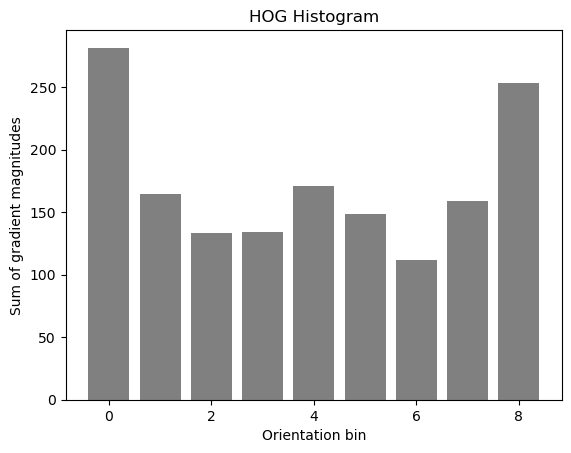

In [9]:
import matplotlib.pyplot as plt

hist = hog_grids[0]

# hist: (nbins, H, W)
bin_totals = hist.sum(dim=(1, 2)).cpu().numpy()  # sum over H, W → shape (nbins,)

plt.bar(range(hist.shape[0]), bin_totals, width=0.8, color='gray')
plt.xlabel("Orientation bin")
plt.ylabel("Sum of gradient magnitudes")
plt.title("HOG Histogram")
plt.show()

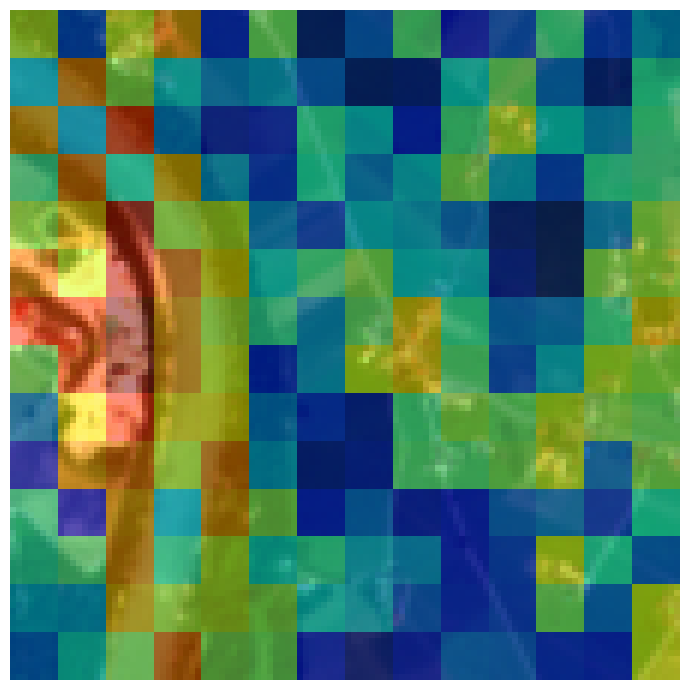

In [ ]:
NBINS = 9
POOL = 8
hog_saliency = HOGSaliency(nbins=NBINS, pool=POOL, in_channels=len(BANDS))
 
hog_saliencies_batch = hog_saliency(imgs_batch)

INDEX = 5
img = imgs_batch[INDEX]
hog_saliency_grid = hog_saliencies_batch[INDEX]

img_rgb = quant_norm(img[band_indices['true_color'], ...]).permute(1, 2, 0).cpu().numpy()
plot_images(generate_saliency_grid(hog_saliency_grid, image=img_rgb))

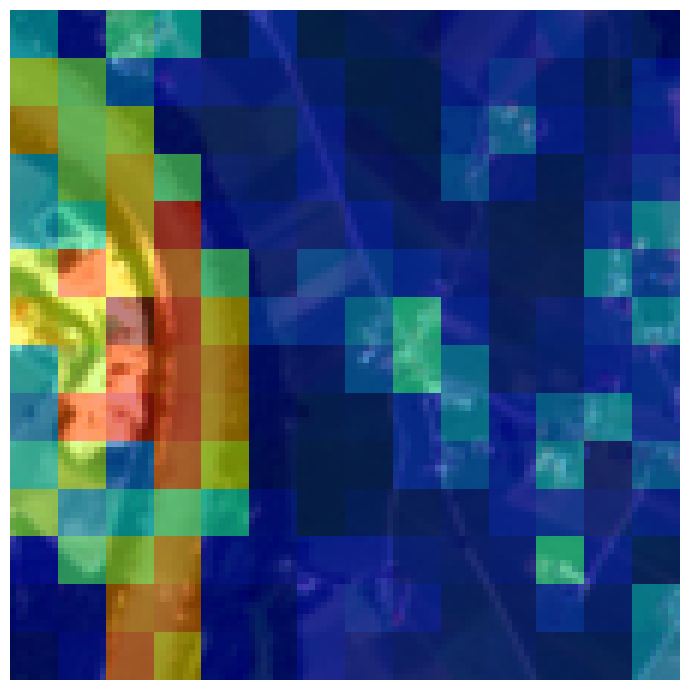

In [10]:
ndi_saliency = NDISaliency(patch_size=POOL, bands=BANDS)

ndi_saliencies_batch = ndi_saliency(imgs_batch)

INDEX = 5
img = imgs_batch[INDEX]
ndi_saliency_grid = ndi_saliencies_batch[INDEX]

img_rgb = quant_norm(img[band_indices['true_color'], ...]).permute(1, 2, 0).cpu().numpy()
plot_images(generate_saliency_grid(ndi_saliency_grid, image=img_rgb))

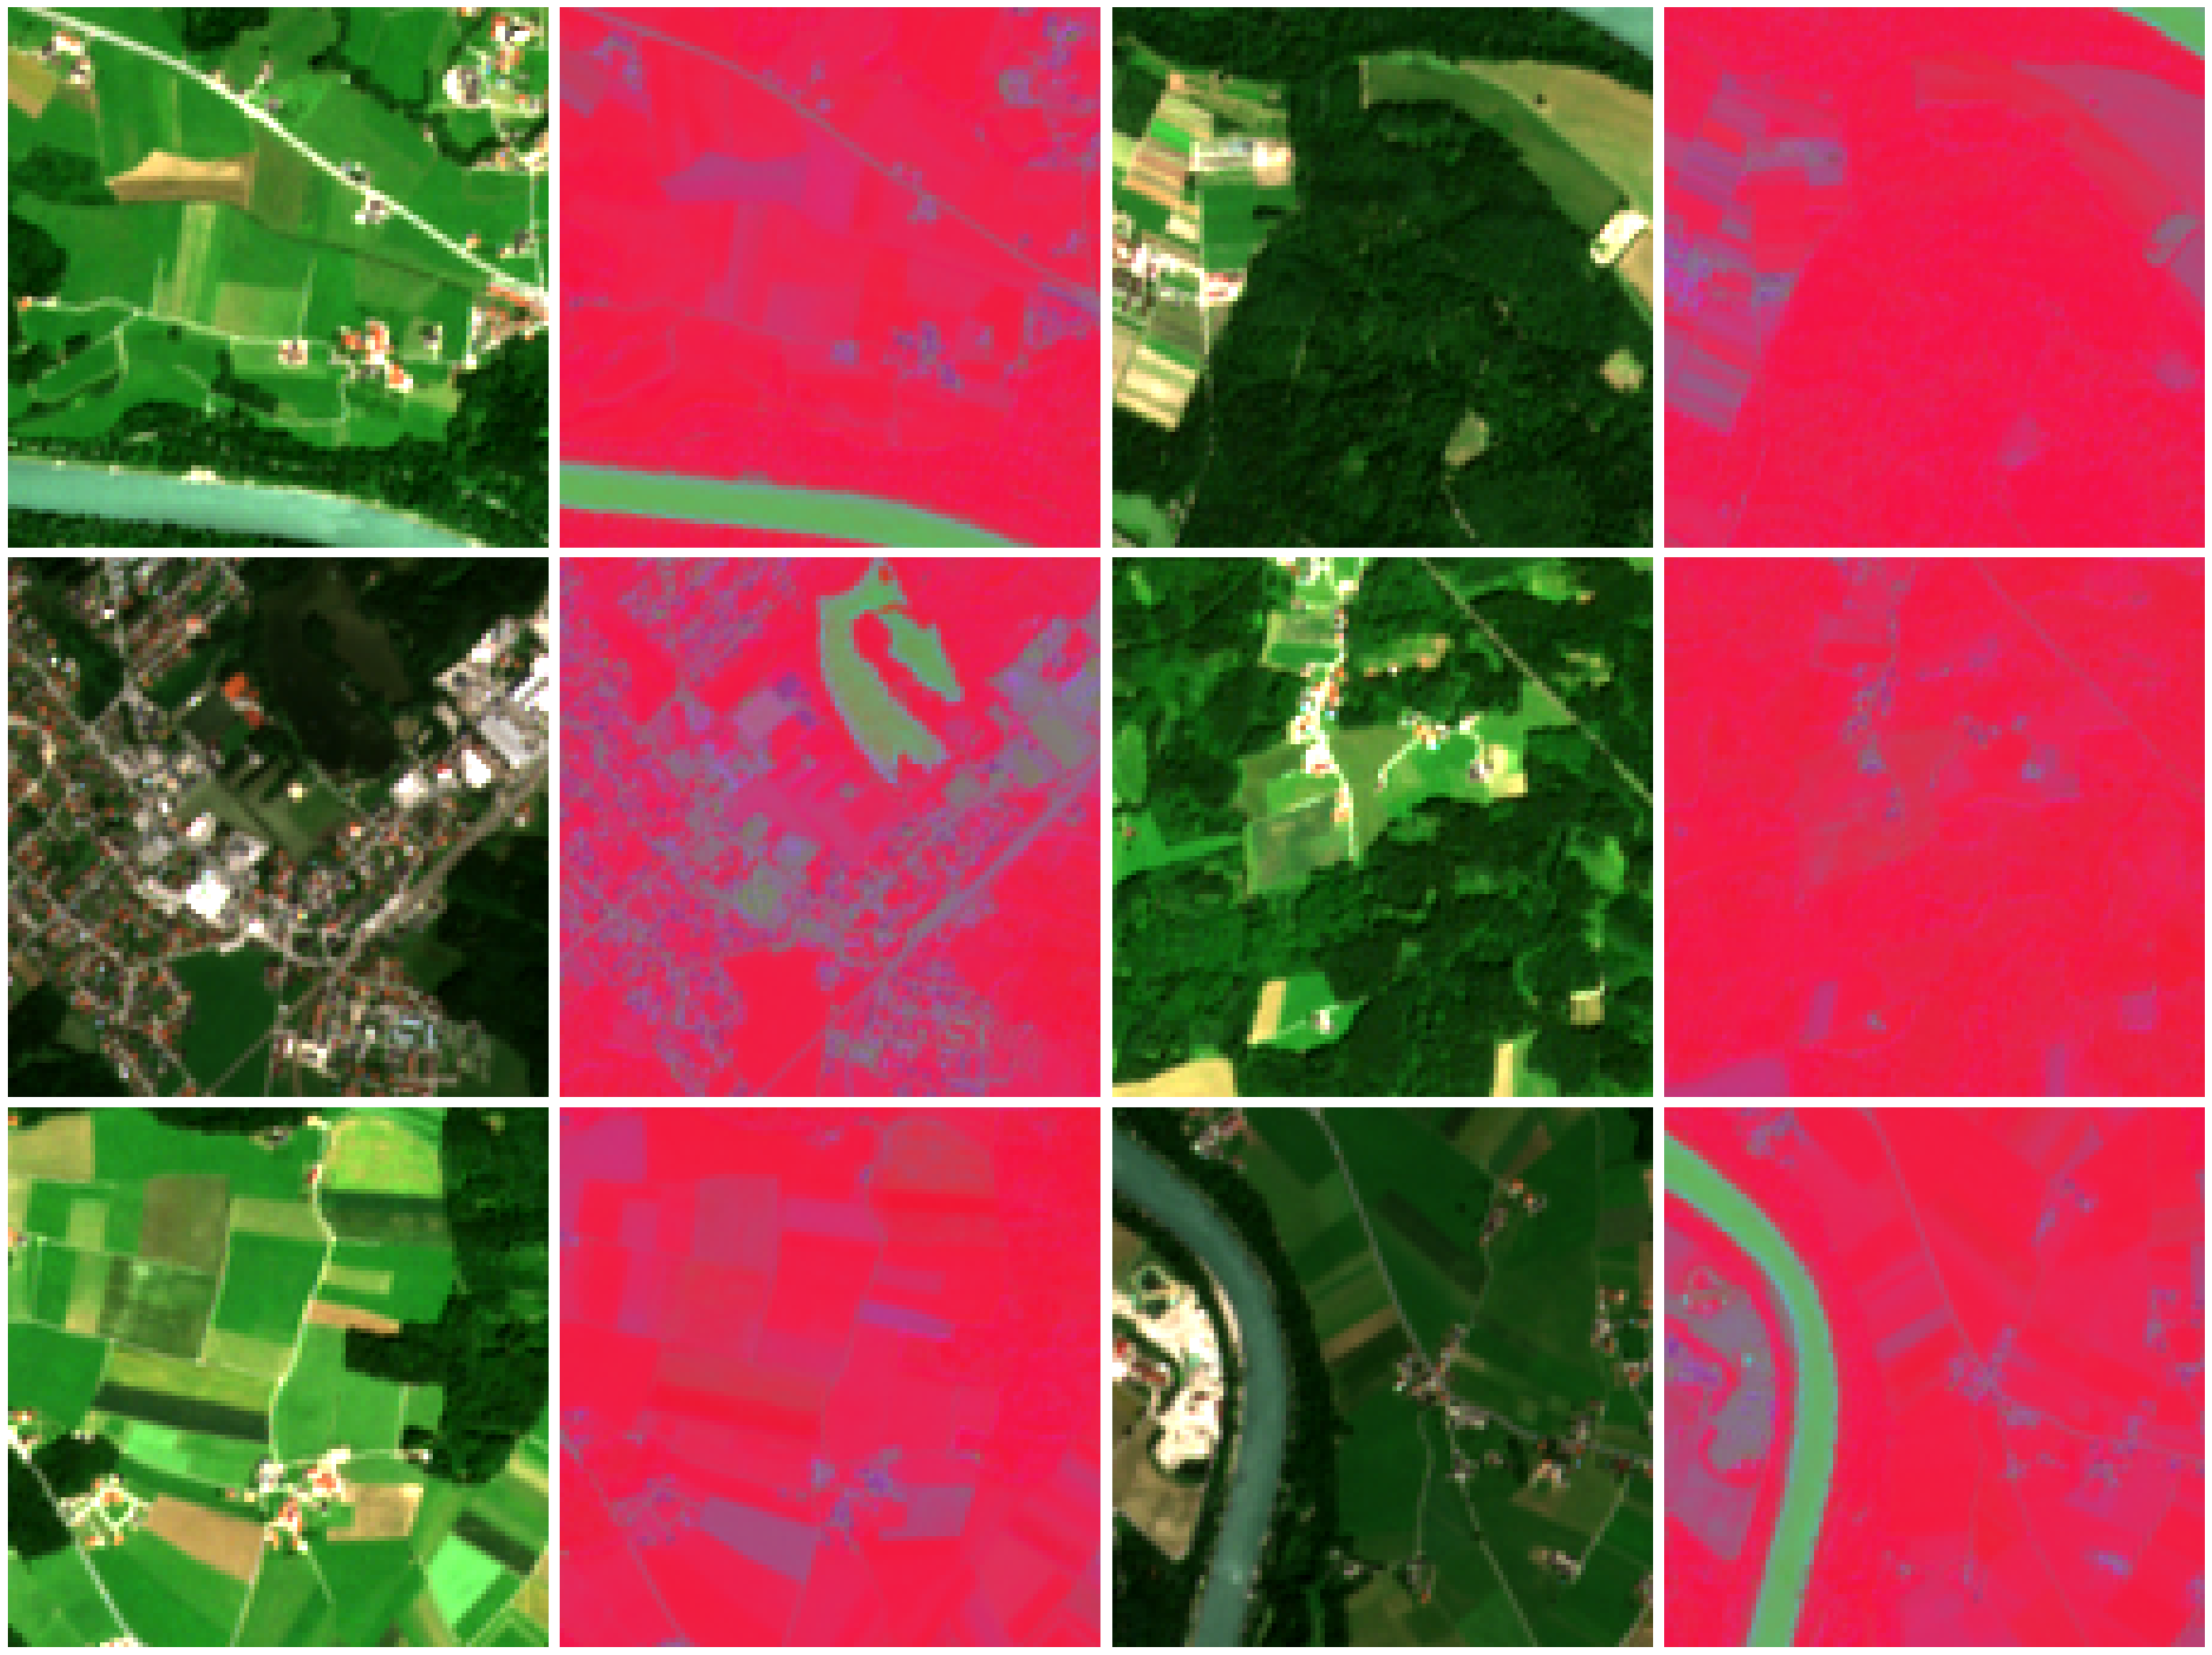

In [6]:
ndi_layer = NDILayer(BANDS)


N=6
ndi_imgs_batch = ndi_layer(imgs_batch[:N])
plot_images(torch.stack([quant_norm(imgs_batch[:N, [3,2,1], ...]),
                         (ndi_imgs_batch+1)/2], dim=0).
                         transpose(0,1).flatten(0,1))

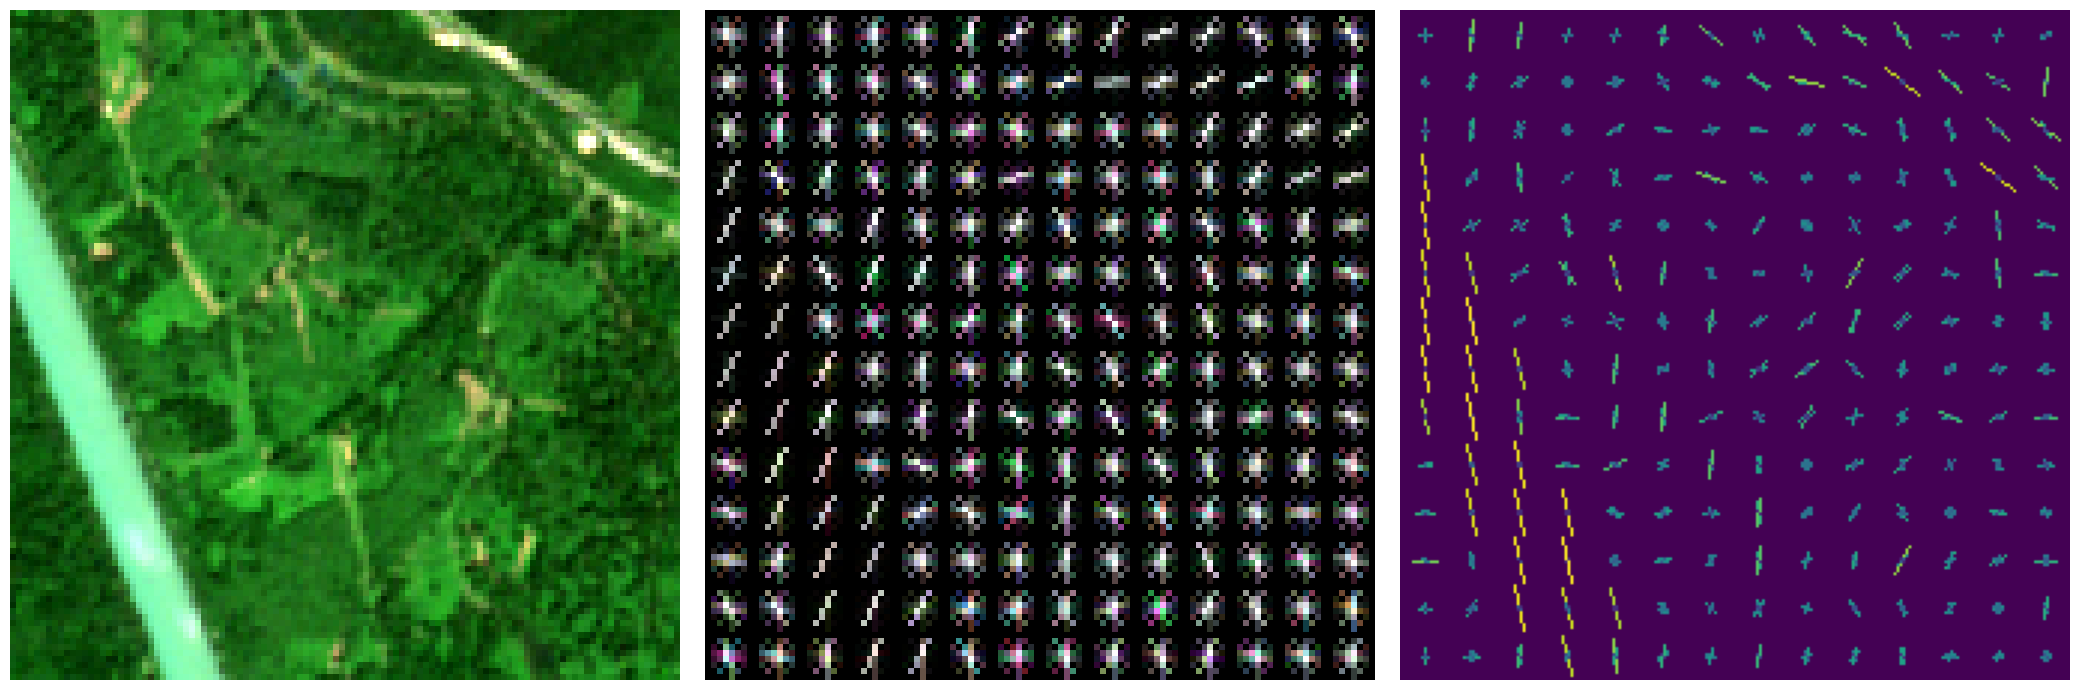

In [88]:
from hog_viz_gemi import *
INDEX = 31

NBINS = 9
POOL = 8
# Assuming BANDS is defined somewhere in your code
hogLayer = HOGLayer(nbins=NBINS, pool=POOL, in_channels=len(BANDS),
                    gaussian_window=None, normalize=True)

# 1. Get the output from your custom layer
hog_output = hogLayer(imgs_batch) # Shape: (B, C, 9, H//8, W//8)

# 2. Generate the normalized RGB image directly 
# (using batch index 3, and assuming channels 3, 2, 1 are your RGB bands)
hog_rgb_visualization = get_rgb_hog_image(
    hog_output, 
    batch_idx=INDEX, 
    rgb_channels=band_indices['true_color'], 
    p_low=0.01, 
    p_high=0.99,
    pool=POOL
)

# 3. Plot it!
# hog_rgb_visualization is now a pristine (H, W, 3) numpy array scaled from 0 to 1
img_rgb = quant_norm(imgs_batch[INDEX][band_indices['true_color'], ...])
my_hog_viz = generate_hog_image(hog_grids_batch[INDEX][band_indices['true_color'], ...])
plot_images([img_rgb, hog_rgb_visualization, my_hog_viz], ncols=3)

